In [7]:

# Step 1: Import libraries
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


In [8]:
# Step 2: Load the dataset
iris = load_iris()
X = iris.data[:, :2]  # Sepal length and sepal width

In [9]:
print("Dataset shape:", X.shape)

Dataset shape: (150, 2)


In [10]:
# Step 3: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [11]:
# Step 4: Apply the Elbow Method
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

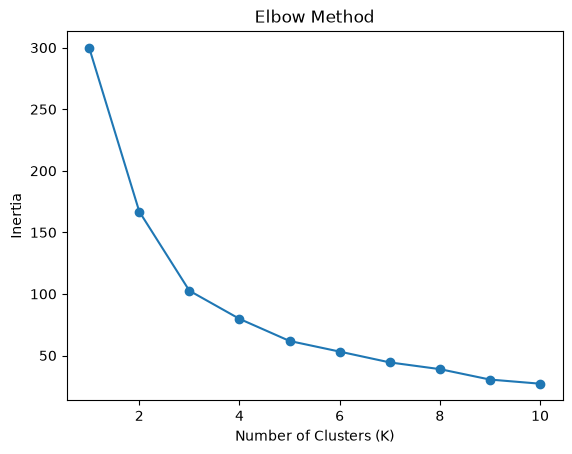

In [12]:
# Step 5: Plot the Elbow graph
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [13]:
# Step 6: Apply K-Means with K = 3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

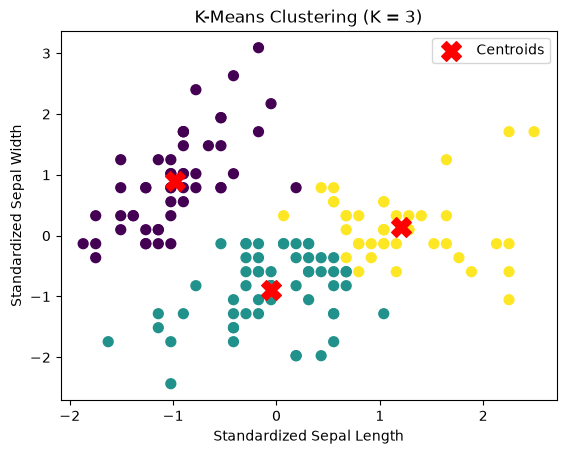

In [14]:
# Step 7: Visualize the clusters
plt.scatter(
    X_scaled[:, 0], X_scaled[:, 1],
    c=clusters, cmap='viridis', s=50
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X', s=200, color='red', label='Centroids'
)

plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Sepal Width")
plt.title("K-Means Clustering (K = 3)")
plt.legend()
plt.show()

In [15]:
print("\nFirst 10 cluster assignments:")
print(clusters[:10])


First 10 cluster assignments:
[0 0 0 0 0 0 0 0 0 0]


In [ ]:
C:\Users\user\Downloads\archive (13)

In [18]:
import pandas as pd
import os

folder_path = r"C:\Users\user\Downloads\archive (13)"

files = os.listdir(folder_path)
print(files)

['Mall_Customers.csv']


In [19]:
df = pd.read_csv(os.path.join(folder_path, files[0]))

print(df)

     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0             1    Male   19                  15                      39
1             2    Male   21                  15                      81
2             3  Female   20                  16                       6
3             4  Female   23                  16                      77
4             5  Female   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83

[200 rows x 5 columns]


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

In [21]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (200, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Statistical Summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


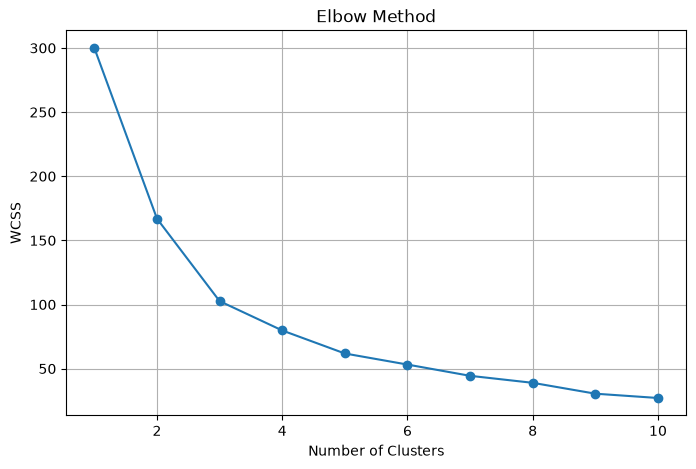

In [22]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [23]:
# Select numerical columns
X = df.select_dtypes(include=np.number)

# Remove columns with all missing values
X = X.dropna(axis=1, how='all')

# Fill missing values
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Preprocessing completed")

Preprocessing completed


In [24]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print(df)

     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0             1    Male   19                  15                      39   
1             2    Male   21                  15                      81   
2             3  Female   20                  16                       6   
3             4  Female   23                  16                      77   
4             5  Female   31                  17                      40   
..          ...     ...  ...                 ...                     ...   
195         196  Female   35                 120                      79   
196         197  Female   45                 126                      28   
197         198    Male   32                 126                      74   
198         199    Male   32                 137                      18   
199         200    Male   30                 137                      83   

     Cluster  
0          0  
1          0  
2          0  
3          0  
4          0

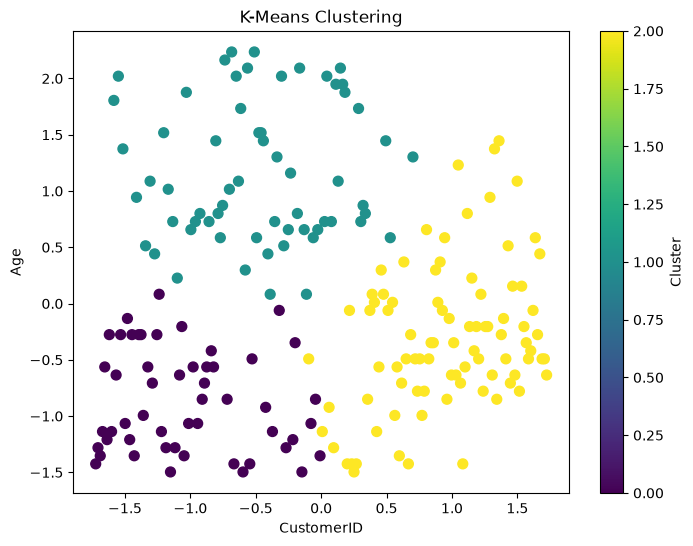

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

plt.title('K-Means Clustering')
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.colorbar(label='Cluster')
plt.show()

In [26]:
print("Cluster Counts:")
print(df['Cluster'].value_counts())

print("\nCluster Mean Values:")
display(df.groupby('Cluster').mean(numeric_only=True))

Cluster Counts:
Cluster
2    86
1    62
0    52
Name: count, dtype: int64

Cluster Mean Values:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,
0,41.384615,26.807692,34.884615,59.211538
1,73.112903,54.983871,49.419355,40.338710
2,155.988372,34.500000,84.116279,51.860465


In [27]:
output_path = os.path.join(folder_path, "kmeans_clustered_dataset.csv")

df.to_csv(output_path, index=False)

print("Clustered dataset saved successfully!")
print(output_path)

Clustered dataset saved successfully!
C:\Users\user\Downloads\archive (13)\kmeans_clustered_dataset.csv
